# Rain over Africa (RoA)

This notebook loads and visualises 15-minute Rain over Africa (RoA) rainfall rate fields over Africa.  
The RoA variable `posterior_mean` represents the posterior mean of the predicted rainfall-rate CDF (**mm h⁻¹**) on a regular lat–lon grid.

RoA files follow the naming convention `MSG3YYYYMMDD-SHHMM-EHHMM.nc`, where the filename encodes the start and end times of each 15-minute retrieval window.


In [48]:
import numpy as np 
from netCDF4 import Dataset
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

import cartopy.crs as ccrs                              
import cartopy.feature as cfeature                   
import cartopy.io.shapereader as shpreader

import warnings
warnings.filterwarnings("ignore")

In [49]:
path_ROA = "/gws/ssde/j25b/swift/RoA"

year = "2023"
month = "04"
day = "10"
hour = "15"
minute = "00"

t0 = datetime(
    int(year), int(month), int(day),
    int(hour), int(minute)
)

t1 = t0 + timedelta(minutes=15)

file_path = (
    f"{path_ROA}/{year}/{month}/"
    f"MSG3{t0:%Y%m%d}"
    f"-S{t0:%H%M}"
    f"-E{t1:%H%M}.nc"
)


# File reading

In [50]:
ds = Dataset(file_path)

lat = ds.variables["latitude"][:]     # shape (Ny,)
lon = ds.variables["longitude"][:]    # shape (Nx,)

roa = ds.variables["posterior_mean"][:]  # shape (Ny, Nx)

In [51]:
CONTEXT_LAT_MIN = -26
CONTEXT_LAT_MAX = -12
CONTEXT_LON_MIN = 40
CONTEXT_LON_MAX = 52

extent = (
    CONTEXT_LON_MIN,
    CONTEXT_LON_MAX,
    CONTEXT_LAT_MIN,
    CONTEXT_LAT_MAX,    
)

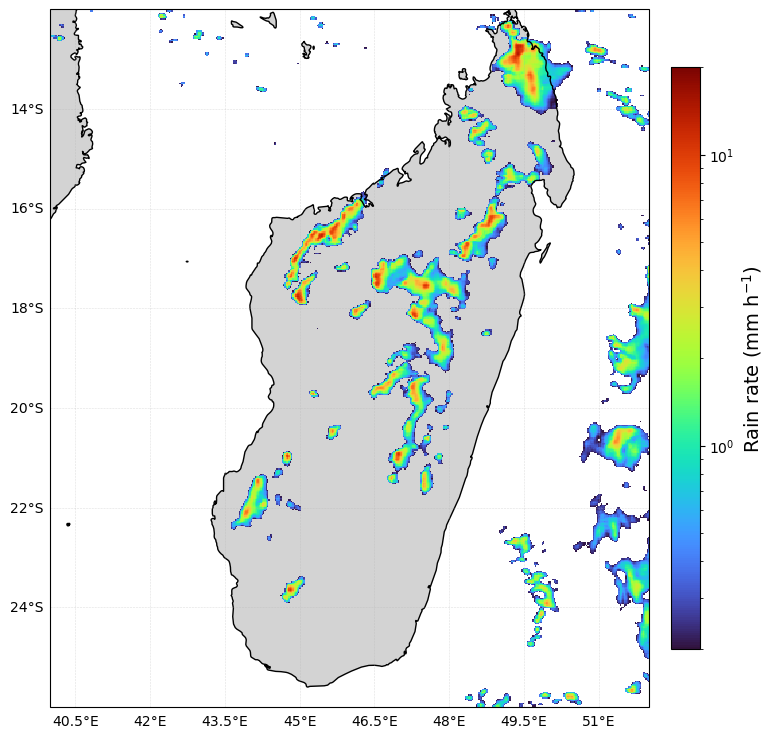

In [52]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import LogNorm

# Create grid
lon2d, lat2d = np.meshgrid(lon, lat)

# Mask weak rain (stronger threshold)
roa_plot = np.ma.masked_less(roa, 0.2)

fig = plt.figure(figsize=(8, 10))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent(extent, crs=ccrs.PlateCarree())

# Clean background
ax.add_feature(cfeature.LAND, facecolor="lightgrey", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="white", zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=1.0, zorder=2)
ax.add_feature(cfeature.BORDERS, linewidth=0.6, zorder=2)

# Gridlines
gl = ax.gridlines(draw_labels=True, linestyle="--", linewidth=0.4, alpha=0.4)
gl.top_labels = False
gl.right_labels = False

# Plot with log scaling (BIG improvement)
im = ax.pcolormesh(
    lon2d,
    lat2d,
    roa_plot,
    transform=ccrs.PlateCarree(),
    cmap="turbo",
    norm=LogNorm(vmin=0.2, vmax=20),
    zorder=1,
)

# Colorbar
cbar = plt.colorbar(im, ax=ax, pad=0.03, shrink=0.6)
cbar.set_label("Rain rate (mm h$^{-1}$)", fontsize=14)

# Styling
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.tight_layout()
plt.show()